# VisNet-Sobel (JSRT)
**Team D3 · Medical Image Analysis**

1. Setup & configuration

In [ ]:
import os, re, glob, json, time, random, math, copy, warnings
from dataclasses import dataclass, asdict
import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision.ops import DeformConv2d
from skimage.metrics import structural_similarity, peak_signal_noise_ratio
from scipy.stats import wilcoxon

SMOKE_TEST = False     
DATA_DIR   = None      

@dataclass
class CFG:
    seed: int = 42
    img_size: int = 256           
    in_ch: int = 1                
    split: tuple = (0.70, 0.15, 0.15)   
    noise_kind: str = 'awgn'       
    sigma: float = 25 / 255
    pg_scale: float = 100.0
    patch: int = 128              
    batch: int = 16
    crops_per_image: int = 2      
    epochs: int = 80
    patience: int = 15            
    min_epochs: int = 25           
    warmup: int = 3               
    lr: float = 1e-3
    offset_lr_mult: float = 0.1    
    grad_clip: float = 1.0
    sobel_lambda: float = 0.05     
    eval_bs: int = 1

cfg = CFG()
if SMOKE_TEST:
    cfg.img_size, cfg.patch, cfg.batch = 128, 64, 4
    cfg.epochs, cfg.patience, cfg.min_epochs, cfg.crops_per_image = 2, 2, 1, 1

def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
seed_everything(cfg.seed)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
OUT_DIR = '/kaggle/working/visnet_out' if os.path.isdir('/kaggle/working') else './visnet_out'
os.makedirs(os.path.join(OUT_DIR, 'figures'), exist_ok=True)
print(f"device = {device} | outputs -> {OUT_DIR}")
print(json.dumps(asdict(cfg), indent=1))

device = cuda | outputs -> /kaggle/working/visnet_out
{
 "seed": 42,
 "img_size": 256,
 "in_ch": 1,
 "split": [
  0.7,
  0.15,
  0.15
 ],
 "noise_kind": "awgn",
 "sigma": 0.09803921568627451,
 "pg_scale": 100.0,
 "patch": 128,
 "batch": 16,
 "crops_per_image": 2,
 "epochs": 80,
 "patience": 15,
 "min_epochs": 25,
 "warmup": 3,
 "lr": 0.001,
 "offset_lr_mult": 0.1,
 "grad_clip": 1.0,
 "sobel_lambda": 0.05,
 "eval_bs": 1
}


2. Data: stratified split 

In [ ]:
IMG_EXT = ('.png', '.jpg', '.jpeg', '.bmp')

def locate_images(hint=None):
    """Find the folder that holds the JSRT radiographs (the one with the most images, 247 expected)."""
    roots = [hint] if hint else ['/kaggle/input', os.getcwd()]
    by_dir = {}
    for r in roots:
        if r and os.path.isdir(r):
            for dp, _, fs in os.walk(r):
                imgs = sorted(os.path.join(dp, f) for f in fs if f.lower().endswith(IMG_EXT))
                if imgs: by_dir[dp] = imgs
    if not by_dir: raise FileNotFoundError("No images found. Add the JSRT Kaggle dataset or set DATA_DIR.")
    d = max(by_dir, key=lambda k: (len(by_dir[k]) == 247, len(by_dir[k])))
    return d, by_dir[d]

raw_dir, all_paths = locate_images(DATA_DIR)
if SMOKE_TEST: all_paths = all_paths[::6]          
print(f"image folder: {raw_dir}\nimages found: {len(all_paths)}  (JSRT should have 247)")

def group_of(p):                       
    return os.path.basename(p)[:5].upper()

def stratified_split(paths, ratios, seed):
    rng = np.random.RandomState(seed); groups = {}
    for p in sorted(paths): groups.setdefault(group_of(p), []).append(p)
    tr, va, te = [], [], []
    for g, ps in sorted(groups.items()):
        ps = list(ps); rng.shuffle(ps); n = len(ps)
        n_te, n_va = int(round(n * ratios[2])), int(round(n * ratios[1]))
        te += ps[:n_te]; va += ps[n_te:n_te + n_va]; tr += ps[n_te + n_va:]
    return sorted(tr), sorted(va), sorted(te)

def composition(paths):
    c = {}
    for p in paths: c[group_of(p)] = c.get(group_of(p), 0) + 1
    return c

old_tr, old_va = sorted(all_paths)[:197], sorted(all_paths)[197:247]
print("\nOLD split (sorted filenames) ->  train:", composition(old_tr), "| val:", composition(old_va))

train_paths, val_paths, test_paths = stratified_split(all_paths, cfg.split, cfg.seed)
print("NEW stratified split ->  train:", composition(train_paths), "| val:", composition(val_paths), "| test:", composition(test_paths))
print(f"sizes: train={len(train_paths)}  val={len(val_paths)}  test={len(test_paths)}  (no image appears in two sets: "
      f"{len(set(train_paths)|set(val_paths)|set(test_paths)) == len(train_paths)+len(val_paths)+len(test_paths)})")

def load_gray(paths, size):
    out = []
    for p in paths:
        im = cv2.imread(p, cv2.IMREAD_GRAYSCALE)
        if im is None: raise IOError(f"cannot read {p}")
        if im.shape != (size, size): im = cv2.resize(im, (size, size), interpolation=cv2.INTER_AREA)
        out.append(im)
    return np.stack(out)               

train_u8, val_u8, test_u8 = (load_gray(p, cfg.img_size) for p in (train_paths, val_paths, test_paths))
print("loaded arrays:", train_u8.shape, val_u8.shape, test_u8.shape)

image folder: /kaggle/input/datasets/raddar/nodules-in-chest-xrays-jsrt/images/images
images found: 247  (JSRT should have 247)

OLD split (sorted filenames) ->  train: {'JPCLN': 154, 'JPCNN': 43} | val: {'JPCNN': 50}
NEW stratified split ->  train: {'JPCLN': 108, 'JPCNN': 65} | val: {'JPCLN': 23, 'JPCNN': 14} | test: {'JPCLN': 23, 'JPCNN': 14}
sizes: train=173  val=37  test=37  (no image appears in two sets: True)
loaded arrays: (173, 256, 256) (37, 256, 256) (37, 256, 256)


3. Model: VisNet with Sobel-guided attention, plus U-Net baseline

In [ ]:
# Sobel operator 
_SOBEL_K = {}
def sobel_grad(x):
    """x: (B,C,H,W) -> (B,C,2,H,W) = (Gx, Gy). Kernel is divided by 8 so values are
    true intensity-per-pixel gradients."""
    key = (x.device, x.dtype)
    if key not in _SOBEL_K:
        kx = torch.tensor([[-1., 0., 1.], [-2., 0., 2.], [-1., 0., 1.]], device=x.device, dtype=x.dtype) / 8.
        _SOBEL_K[key] = torch.stack([kx, kx.t()]).unsqueeze(1)          # (2,1,3,3)
    B, C, H, W = x.shape
    g = F.conv2d(F.pad(x.reshape(B * C, 1, H, W), (1, 1, 1, 1), mode='replicate'), _SOBEL_K[key])
    return g.reshape(B, C, 2, H, W)

def sobel_mag(x):
    g = sobel_grad(x)
    return torch.sqrt(g[:, :, 0] ** 2 + g[:, :, 1] ** 2 + 1e-8)

def sobel_loss(out, target):
    """Edge-consistency loss: L1 between Sobel gradients of prediction and ground truth."""
    return (sobel_grad(out) - sobel_grad(target)).abs().mean()

#  VisNet building blocks
class DeformBlock(nn.Module):
    """5x5 deformable conv. Offsets come from a zero-initialised 3x3 conv, so at init this is
    exactly a plain 5x5 conv (same trick as the original implementation)."""
    def __init__(self, inc, outc, k=5):
        super().__init__()
        self.offset = nn.Conv2d(inc, 2 * k * k, 3, padding=1)
        nn.init.zeros_(self.offset.weight); nn.init.zeros_(self.offset.bias)
        self.dcn = DeformConv2d(inc, outc, k, padding=k // 2, bias=False)
    def forward(self, x):
        return self.dcn(x, self.offset(x))

def _seq2(i, o, k1, k2):
    return nn.Sequential(nn.Conv2d(i, o, k1, padding=k1 // 2), nn.ReLU(True),
                         nn.Conv2d(o, o, k2, padding=k2 // 2), nn.ReLU(True))

class Mdense_conv(nn.Module):            # magnocellular
    def __init__(self, i, o): super().__init__(); self.conv = _seq2(i, o, 3, 3)
    def forward(self, x): return self.conv(x)

class Pdense_conv(nn.Module):            # parvocellular
    def __init__(self, i, o): super().__init__(); self.conv = _seq2(i, o, 1, 3)
    def forward(self, x): return self.conv(x)

class Ventral_conv(nn.Module):
    def __init__(self, i, o):
        super().__init__()
        self.conv = nn.Sequential(nn.Conv2d(i, o, 1), nn.ReLU(True),
                                  nn.Conv2d(o, o, 3, padding=1), nn.ReLU(True),
                                  nn.Conv2d(o, o, 3, padding=1), nn.ReLU(True))
    def forward(self, x): return self.conv(x)

class Fusion_conv(nn.Module):
    def __init__(self, i, mid, out_ch):
        super().__init__()
        self.conv = nn.Sequential(nn.Conv2d(i, mid, 1), nn.ReLU(True),
                                  nn.Conv2d(mid, out_ch, 3, padding=1))   
    def forward(self, x, y): return self.conv(torch.cat((x, y), 1))

class SpatialAttn(nn.Module):
    """Original spatial attention uses [channel-max, channel-mean]. With sobel=True a third map,
    the Sobel gradient magnitude of the channel-mean, tells the attention WHERE the edges are."""
    def __init__(self, out_ch, k=5, sobel=False):
        super().__init__()
        self.sobel = sobel
        self.conv = nn.Conv2d(3 if sobel else 2, out_ch, k, padding=k // 2, bias=False)
        self.norm = nn.InstanceNorm2d(out_ch, eps=1e-5, affine=False)
    def forward(self, x):
        mean = x.mean(1, keepdim=True)
        maps = [x.max(1, keepdim=True)[0], mean]
        if self.sobel: maps.append(sobel_mag(mean))
        return torch.sigmoid(F.relu(self.norm(self.conv(torch.cat(maps, 1)))))

class DB_Conv(nn.Module):
    def __init__(self, i, g):
        super().__init__(); self.conv = nn.Sequential(nn.Conv2d(i, g, 3, padding=1), nn.ReLU(True))
    def forward(self, x): return torch.cat((x, self.conv(x)), 1)

class DB(nn.Module):
    def __init__(self, n_layer, n_feats=32, rate=32):
        super().__init__()
        self.convs = nn.Sequential(*[DB_Conv(n_feats + n * rate, rate) for n in range(n_layer)])
        self.LFF = nn.Conv2d(n_feats + n_layer * rate, n_feats, 1)
    def forward(self, x): return self.LFF(self.convs(x)) + x

class Edge_Net(nn.Module):
    def __init__(self, in_ch, n_feats=32, n_layer=3):
        super().__init__()
        self.trans = nn.Conv2d(in_ch, n_feats, 3, padding=1)
        self.rdb = DB(n_layer, n_feats)
        self.rebuilt = nn.Conv2d(n_feats, in_ch, 3, padding=1)
    def forward(self, x): return x + self.rebuilt(self.rdb(self.trans(x)))

class VisNet(nn.Module):
    """VisNet / DPN re-implementation"""
    def __init__(self, in_ch=1, sobel_attn=False):
        super().__init__()
        c = in_ch
        self.mdense1, self.pdense1 = Mdense_conv(c, 32), Pdense_conv(c, 32)
        self.mdense2, self.pdense2 = Mdense_conv(32, c), Pdense_conv(32, c)
        self.mv1, self.mv2, self.mv3 = DeformBlock(c, 16), DeformBlock(16, 32), DeformBlock(32, c)
        self.Edge_Net1 = Edge_Net(c)
        self.sa1, self.sa2, self.sa3 = (SpatialAttn(c, sobel=sobel_attn), SpatialAttn(16, sobel=sobel_attn),
                                        SpatialAttn(32, sobel=sobel_attn))
        self.conv1, self.conv2, self.conv3 = nn.Conv2d(c, c, 1), nn.Conv2d(c, 16, 1), nn.Conv2d(32, 32, 1)
        self.ventral_conv1, self.ventral_conv2, self.ventral_conv3 = Ventral_conv(2 * c, c), Ventral_conv(2 * c, 16), Ventral_conv(16, 32)
        self.fusion = Fusion_conv(64, 16, c)

    def forward(self, x):
        m = self.mdense2(self.mdense1(x)) + x
        p = self.pdense2(self.pdense1(x)) + x
        medge = self.Edge_Net1(m) + m
        pedge = self.Edge_Net1(p) + p
        m = self.mv3(self.mv2(self.mv1(m))) + medge + m
        p = self.mv3(self.mv2(self.mv1(p))) + pedge + p
        sa1 = self.sa1(m) + self.conv1(m)
        v1 = torch.cat((self.ventral_conv1(torch.cat((m, p), 1)), sa1), 1)
        sa2 = self.sa2(sa1) + self.conv2(sa1)
        v2 = self.ventral_conv2(v1)
        d2 = torch.cat((v2, sa2), 1)
        sa3 = self.sa3(d2) + self.conv3(d2)
        v3 = self.ventral_conv3(v2)
        return self.fusion(sa3, v3)

#  U-Net baseline 
class SmallUNet(nn.Module):
    def __init__(self, in_ch=1, base=8):
        super().__init__()
        b = base
        blk = lambda i, o: nn.Sequential(nn.Conv2d(i, o, 3, padding=1), nn.ReLU(True), nn.Conv2d(o, o, 3, padding=1), nn.ReLU(True))
        self.e1, self.e2, self.e3, self.bott = blk(in_ch, b), blk(b, 2 * b), blk(2 * b, 4 * b), blk(4 * b, 8 * b)
        self.d3, self.d2, self.d1 = blk(12 * b, 4 * b), blk(6 * b, 2 * b), blk(3 * b, b)
        self.out = nn.Conv2d(b, in_ch, 1)
    def forward(self, x):
        up = lambda t, r: F.interpolate(t, size=r.shape[-2:], mode='bilinear', align_corners=False)
        e1 = self.e1(x); e2 = self.e2(F.max_pool2d(e1, 2)); e3 = self.e3(F.max_pool2d(e2, 2))
        b = self.bott(F.max_pool2d(e3, 2))
        d3 = self.d3(torch.cat([up(b, e3), e3], 1)); d2 = self.d2(torch.cat([up(d3, e2), e2], 1))
        d1 = self.d1(torch.cat([up(d2, e1), e1], 1))
        return x + self.out(d1)         

def count_params(m): return sum(p.numel() for p in m.parameters() if p.requires_grad)

def unet_matching(target_params, in_ch=1):
    best = min(range(2, 40), key=lambda b: abs(count_params(SmallUNet(in_ch, b)) - target_params))
    return SmallUNet(in_ch, best), best

@torch.no_grad()
def count_gmacs(model, size=256, in_ch=1):
    """Multiply-accumulates (G) of all conv / deformable-conv layers for one size x size image."""
    m = copy.deepcopy(model).cpu().eval(); tot = [0]
    def hook(mod, inp, out):
        k = mod.kernel_size; k = k if isinstance(k, tuple) else (k, k)
        tot[0] += out.numel() * (mod.in_channels // mod.groups) * k[0] * k[1]
    for mod in m.modules():
        if isinstance(mod, (nn.Conv2d, DeformConv2d)): mod.register_forward_hook(hook)
    m(torch.zeros(1, in_ch, size, size))
    return tot[0] / 1e9

## 4. Noise model and metrics

In [ ]:
# Noise model
def _randn_like(x, gen):
    return torch.randn_like(x) if gen is None else torch.randn(x.shape, generator=gen, dtype=x.dtype)

def degrade(x, kind='awgn', sigma=25/255, pg_scale=100.0, gen=None):
    """x in [0,1]. 'awgn': y = x + N(0, sigma^2).  'pg': Poisson(x*scale)/scale + N(0, sigma^2).
    No clipping (standard AWGN benchmark protocol)."""
    if kind == 'awgn':
        return x + sigma * _randn_like(x, gen)
    if kind == 'pg':
        lam = x.clamp(0, 1) * pg_scale
        p = torch.poisson(lam) if gen is None else torch.poisson(lam, generator=gen)
        return p / pg_scale + sigma * _randn_like(x, gen)
    raise ValueError(kind)

def to_tensor(u8):                     
    return torch.from_numpy(u8).float().div(255.).unsqueeze(1)

def fixed_noisy(u8, kind, sigma, seed, pg_scale=100.0):
    """Deterministic noisy copy (same noise every call) -> val/test sets are reproducible."""
    gen = torch.Generator().manual_seed(seed)
    clean = to_tensor(u8)
    return degrade(clean, kind, sigma, pg_scale, gen), clean

val_noisy,  val_clean  = fixed_noisy(val_u8,  cfg.noise_kind, cfg.sigma, seed=1001, pg_scale=cfg.pg_scale)
test_noisy, test_clean = fixed_noisy(test_u8, cfg.noise_kind, cfg.sigma, seed=2002, pg_scale=cfg.pg_scale)

# Metrics 
def quantize(x):                       
    return (x.clamp(0, 1) * 255).round() / 255

def psnr_per_image(a, b):              
    mse = ((a - b) ** 2).mean(dim=(1, 2, 3))
    return -10 * torch.log10(mse + 1e-12)

def full_metrics(out, clean):
    """Authors' protocol: full image, clamp, 8-bit quantise, skimage PSNR / SSIM (data_range=255).
    + RMSE and an edge-fidelity score (PSNR between Sobel magnitude maps)."""
    out_q, cl_q = quantize(out), quantize(clean)
    o8 = (out_q * 255).squeeze(1).numpy().astype(np.uint8); c8 = (cl_q * 255).squeeze(1).numpy().astype(np.uint8)
    psnr = np.array([peak_signal_noise_ratio(c, o, data_range=255) for c, o in zip(c8, o8)])
    ssim = np.array([structural_similarity(c, o, data_range=255) for c, o in zip(c8, o8)])
    rmse = ((out_q - cl_q) ** 2).mean(dim=(1, 2, 3)).sqrt().numpy()
    e_mse = ((sobel_mag(out_q) - sobel_mag(cl_q)) ** 2).mean(dim=(1, 2, 3)).numpy()
    edge_psnr = -10 * np.log10(e_mse + 1e-12)
    return dict(psnr=psnr, ssim=ssim, rmse=rmse, edge_psnr=edge_psnr)

@torch.no_grad()
def predict(model, noisy, bs=1):
    model.eval(); outs = []
    for i in range(0, len(noisy), bs):
        outs.append(model(noisy[i:i + bs].to(device)).float().clamp(0, 1).cpu())
    return torch.cat(outs)

@torch.no_grad()
def ms_per_image(model, sample, reps=5):
    model.eval(); x = sample[:1].to(device); model(x)
    if device.type == 'cuda': torch.cuda.synchronize()
    t = time.time()
    for _ in range(reps): model(x)
    if device.type == 'cuda': torch.cuda.synchronize()
    return (time.time() - t) / reps * 1000

noisy_m = full_metrics(test_noisy.clamp(0, 1), test_clean)
print(f"Reference: the NOISY test images themselves score  PSNR {noisy_m['psnr'].mean():.2f} dB | SSIM {noisy_m['ssim'].mean():.4f}")

Reference: the NOISY test images themselves score  PSNR 20.65 dB | SSIM 0.2619


## 5. Sanity checks

In [ ]:
torch.manual_seed(0)
blk = DeformBlock(3, 8); x = torch.randn(2, 3, 20, 20)
assert (blk(x) - F.conv2d(x, blk.dcn.weight, padding=2)).abs().max() < 1e-4, "deform conv != conv at init"

ramp = (0.01 * torch.arange(32).float()).view(1, 1, 1, 32).repeat(1, 1, 32, 1)     # I(x,y) = 0.01 * x
g = sobel_grad(ramp)[0, 0, :, 10, 10]
assert abs(g[0].item() - 0.01) < 1e-6 and abs(g[1].item()) < 1e-6, "Sobel gradient incorrect"

for s in (False, True):
    m = VisNet(cfg.in_ch, sobel_attn=s)
    y = m(torch.rand(2, cfg.in_ch, 40, 40))
    assert y.shape == (2, cfg.in_ch, 40, 40)
    assert (y != 0).float().mean() > 0.5, "network output is dead at init"

base_m, sobel_m = VisNet(cfg.in_ch, False), VisNet(cfg.in_ch, True)
P_BASE = count_params(base_m)
unet_m, unet_base = unet_matching(P_BASE, cfg.in_ch)
print(f"VisNet baseline      : {P_BASE/1e6:.4f} M params | {count_gmacs(base_m, 256, cfg.in_ch):.2f} GMACs @256x256")
print(f"VisNet + Sobel attn  : {count_params(sobel_m)/1e6:.4f} M params (+{count_params(sobel_m)-P_BASE:,}, "
      f"{100*(count_params(sobel_m)-P_BASE)/P_BASE:.2f}% overhead)")
print(f"U-Net (param-matched): {count_params(unet_m)/1e6:.4f} M params (base={unet_base})")
print(f"(3-channel RGB version of VisNet = {count_params(VisNet(3))/1e6:.4f} M -> matches the paper's ~0.15 M)")
del base_m, sobel_m, unet_m
print("sanity checks passed")

VisNet baseline      : 0.1440 M params | 15.69 GMACs @256x256
VisNet + Sobel attn  : 0.1453 M params (+1,225, 0.85% overhead)
U-Net (param-matched): 0.1543 M params (base=9)
(3-channel RGB version of VisNet = 0.1506 M -> matches the paper's ~0.15 M)
sanity checks passed


## 6. Training utilities and fixed early stopping

In [ ]:
class AverageMeter:
    def __init__(self): self.sum = 0.0; self.n = 0
    def update(self, v, n=1): self.sum += v * n; self.n += n
    @property
    def avg(self): return self.sum / max(self.n, 1)

class EarlyStopping:
    """Fixed early stopping.
    - tracks the best epoch/value and keeps the best weights in memory (restored at the end)
    - `step()` returns True when there has been no improvement for `patience` epochs
      AND at least `min_epochs` epochs have run. The decision is re-evaluated every epoch,
      it is NOT a sticky flag (the old code latched `early_stop=True` and then ignored it until epoch 100).
    mode='max' monitors a score such as val PSNR; mode='min' monitors a loss."""
    def __init__(self, patience=20, min_epochs=0, min_delta=0.0, mode='max'):
        assert mode in ('max', 'min')
        self.patience, self.min_epochs, self.min_delta, self.mode = patience, min_epochs, min_delta, mode
        self.best, self.best_epoch, self.counter, self.best_state = None, 0, 0, None
    def _better(self, v):
        if self.best is None: return True
        return v > self.best + self.min_delta if self.mode == 'max' else v < self.best - self.min_delta
    def step(self, value, model, epoch):
        if self._better(value):
            self.best, self.best_epoch, self.counter = value, epoch, 0
            self.best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            self.counter += 1
        return self.counter >= self.patience and epoch >= self.min_epochs
    def restore(self, model):
        model.load_state_dict(self.best_state)

class PatchDataset(Dataset):
    """Random crop + horizontal flip only (vertical flips / transposes create anatomically impossible chest
    X-rays). Returns CLEAN patches only; noise is added on the GPU, fresh every iteration."""
    def __init__(self, imgs_u8, patch, repeats=1):
        self.imgs, self.patch, self.repeats = imgs_u8, patch, repeats
    def __len__(self): return len(self.imgs) * self.repeats
    def __getitem__(self, i):
        im = self.imgs[i % len(self.imgs)]; H, W = im.shape; ps = min(self.patch, H, W)
        y, x = random.randint(0, H - ps), random.randint(0, W - ps)
        p = im[y:y + ps, x:x + ps]
        if random.random() < .5: p = p[:, ::-1]
        return torch.from_numpy(np.ascontiguousarray(p)).float().div_(255.).unsqueeze(0)

def train_model(name, model, sobel_lambda=0.0, log_every=5):
    model.to(device)
    loader = DataLoader(PatchDataset(train_u8, cfg.patch, cfg.crops_per_image), batch_size=cfg.batch,
                        shuffle=True, drop_last=True, num_workers=0, pin_memory=(device.type == 'cuda'))
    off = [p for n, p in model.named_parameters() if '.offset.' in n]
    base = [p for n, p in model.named_parameters() if '.offset.' not in n]
    groups = [{'params': base, 'lr': cfg.lr}] + ([{'params': off, 'lr': cfg.lr * cfg.offset_lr_mult}] if off else [])
    opt = torch.optim.Adam(groups)
    cos = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=max(cfg.epochs - cfg.warmup, 1), eta_min=1e-6)
    sched = (torch.optim.lr_scheduler.SequentialLR(
                 opt, [torch.optim.lr_scheduler.LinearLR(opt, start_factor=0.1, total_iters=cfg.warmup), cos],
                 milestones=[cfg.warmup]) if cfg.warmup > 0 else cos)
    es = EarlyStopping(cfg.patience, cfg.min_epochs, min_delta=1e-3, mode='max')     # monitor val PSNR (dB)
    hist = dict(epoch=[], lr=[], train_mse=[], val_mse=[], val_psnr=[]); t0 = time.time(); stopped = False

    for epoch in range(1, cfg.epochs + 1):
        model.train(); tl, sl = AverageMeter(), AverageMeter()
        for clean in loader:
            clean = clean.to(device, non_blocking=True)
            noisy = degrade(clean, cfg.noise_kind, cfg.sigma, cfg.pg_scale)          
            out = model(noisy)
            mse = F.mse_loss(out, clean)
            sob = sobel_lambda * sobel_loss(out, clean) if sobel_lambda > 0 else torch.zeros((), device=device)
            loss = mse + sob
            if not torch.isfinite(loss): raise RuntimeError(f"[{name}] loss became NaN/inf at epoch {epoch}")
            opt.zero_grad(set_to_none=True); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), cfg.grad_clip); opt.step()
            tl.update(mse.item(), clean.size(0)); sl.update(sob.item(), clean.size(0))
        lr_now = opt.param_groups[0]['lr']; sched.step()

        v_out = predict(model, val_noisy, cfg.eval_bs)                                
        v_mse = ((v_out - val_clean) ** 2).mean().item(); v_psnr = psnr_per_image(v_out, val_clean).mean().item()
        for k, v in zip(hist, (epoch, lr_now, tl.avg, v_mse, v_psnr)): hist[k].append(v)
        stop = es.step(v_psnr, model, epoch)
        if epoch % log_every == 0 or es.best_epoch == epoch or stop or epoch == cfg.epochs:
            print(f"[{name}] ep {epoch:3d}/{cfg.epochs} | lr {lr_now:.1e} | train MSE {tl.avg:.2e} | val MSE {v_mse:.2e} | "
                  f"val PSNR {v_psnr:6.2f} dB {'*' if es.best_epoch == epoch else ' '} | no-improve {es.counter}/{cfg.patience}"
                  + (f" | Sobel/MSE {sl.avg / max(tl.avg, 1e-12):.2f}x" if sobel_lambda > 0 else ""))
        if stop:
            print(f"[{name}] early stop at epoch {epoch} (best epoch {es.best_epoch}, val PSNR {es.best:.2f} dB)"); stopped = True; break

    es.restore(model)                                                                
    slug = re.sub(r'[^a-z0-9]+', '_', name.lower()).strip('_')
    torch.save(es.best_state, os.path.join(OUT_DIR, f'ckpt_{slug}.pth'))
    return dict(hist=hist, best_epoch=es.best_epoch, best_val_psnr=es.best, stopped_early=stopped,
                epochs_run=len(hist['epoch']), minutes=(time.time() - t0) / 60)

In [ ]:
# fixed EarlyStopping (for testing)
class _Dummy(nn.Module):
    def __init__(self): super().__init__(); self.w = nn.Parameter(torch.zeros(1))
_m = _Dummy()
def _run(seq, **kw):
    es = EarlyStopping(**kw)
    for ep, v in enumerate(seq, 1):
        _m.w.data.fill_(float(ep))
        if es.step(v, _m, ep): return ep, es
    return None, es

ep, es = _run([1, 2, 3, 3, 3, 3, 3, 3, 3, 3], patience=5, min_epochs=0, mode='max')
assert ep == 8 and es.best_epoch == 3, (ep, es.best_epoch)

ep, es = _run([1, 1, 1, 1, 1, 9, 9, 9, 9, 9], patience=3, min_epochs=6, mode='max')
assert ep == 9 and es.best_epoch == 6, (ep, es.best_epoch)

ep, es = _run([5, 4, 4, 4, 4, 4, 4, 4], patience=2, min_epochs=6, mode='max')
assert ep == 6, ep

ep, es = _run([1, 2, 3, 2, 2, 2, 2], patience=3, mode='max'); es.restore(_m)
assert _m.w.item() == 3.0
print("EarlyStopping unit tests passed")

EarlyStopping unit tests passed


## 7. Train all variants (ablation) and the U-Net baseline

In [ ]:
# Experiments: ablation of the two Sobel integrations + a param-matched U-Net baseline 
PROPOSED = 'VisNet + Sobel (attn + loss)'         
VARIANTS = {   
    'VisNet (baseline)':            (dict(sobel_attn=False), 0.0),
    '+ Sobel loss only':            (dict(sobel_attn=False), cfg.sobel_lambda),
    '+ Sobel attention only':       (dict(sobel_attn=True),  0.0),
    PROPOSED:                       (dict(sobel_attn=True),  cfg.sobel_lambda),
}
RUN_UNET = True

RESULTS = {}
for name, (kw, lam) in VARIANTS.items():
    seed_everything(cfg.seed)                      
    m = VisNet(cfg.in_ch, **kw)
    RESULTS[name] = train_model(name, m, sobel_lambda=lam); RESULTS[name]['model'] = m
if RUN_UNET:
    seed_everything(cfg.seed)
    m, _ = unet_matching(count_params(VisNet(cfg.in_ch)), cfg.in_ch)
    RESULTS['U-Net (param-matched)'] = train_model('U-Net (param-matched)', m); RESULTS['U-Net (param-matched)']['model'] = m

print("\n" + pd.DataFrame({k: dict(best_epoch=v['best_epoch'], epochs_run=v['epochs_run'], early_stopped=v['stopped_early'],
      best_val_psnr=round(v['best_val_psnr'], 3), minutes=round(v['minutes'], 1)) for k, v in RESULTS.items()}).T.to_string())

[VisNet (baseline)] ep   1/80 | lr 1.0e-04 | train MSE 3.12e-01 | val MSE 2.19e-01 | val PSNR   6.61 dB * | no-improve 0/15
[VisNet (baseline)] ep   2/80 | lr 4.0e-04 | train MSE 9.00e-02 | val MSE 4.94e-02 | val PSNR  13.07 dB * | no-improve 0/15
[VisNet (baseline)] ep   3/80 | lr 7.0e-04 | train MSE 1.95e-02 | val MSE 4.94e-03 | val PSNR  23.12 dB * | no-improve 0/15
[VisNet (baseline)] ep   4/80 | lr 1.0e-03 | train MSE 5.20e-03 | val MSE 2.16e-03 | val PSNR  26.82 dB * | no-improve 0/15
[VisNet (baseline)] ep   5/80 | lr 1.0e-03 | train MSE 3.05e-03 | val MSE 2.88e-03 | val PSNR  25.51 dB   | no-improve 1/15
[VisNet (baseline)] ep   6/80 | lr 1.0e-03 | train MSE 1.85e-03 | val MSE 1.52e-03 | val PSNR  28.53 dB * | no-improve 0/15
[VisNet (baseline)] ep   7/80 | lr 1.0e-03 | train MSE 1.12e-03 | val MSE 1.37e-03 | val PSNR  28.99 dB * | no-improve 0/15
[VisNet (baseline)] ep   8/80 | lr 9.9e-04 | train MSE 8.68e-04 | val MSE 1.11e-03 | val PSNR  30.03 dB * | no-improve 0/15
[VisNet 

## 8. Test-set evaluation

In [ ]:
# TEST-set evaluation
from skimage.restoration import denoise_nl_means

def estimate_noise_sigma(a):
    """Immerkaer's fast noise-level estimate (pure NumPy/OpenCV, no extra dependencies)."""
    k = np.array([[1, -2, 1], [-2, 4, -2], [1, -2, 1]], np.float64)
    h, w = a.shape
    return float(np.sqrt(np.pi / 2) / (6.0 * (w - 2) * (h - 2)) * np.abs(cv2.filter2D(a, -1, k))[1:-1, 1:-1].sum())
RUN_NLM = True
per_img, outputs, rows = {}, {}, []

def add_row(name, out, model=None):
    met = full_metrics(out, test_clean); per_img[name] = met; outputs[name] = out
    rows.append({'Method': name,
                 'Params (M)': round(count_params(model) / 1e6, 3) if model is not None else '-',
                 'GMACs@256': round(count_gmacs(model, 256, cfg.in_ch), 2) if model is not None else '-',
                 'PSNR (dB)': f"{met['psnr'].mean():.2f} ± {met['psnr'].std():.2f}",
                 'SSIM': f"{met['ssim'].mean():.4f} ± {met['ssim'].std():.4f}",
                 'Edge-PSNR (dB)': f"{met['edge_psnr'].mean():.2f}",
                 'ms/img': round(ms_per_image(model, test_noisy), 1) if model is not None else '-'})

def gauss_denoise(noisy, s):
    return torch.stack([torch.from_numpy(cv2.GaussianBlur(n[0].numpy(), (0, 0), s)).unsqueeze(0) for n in noisy])

add_row('Noisy input', test_noisy.clamp(0, 1))
best_s = max([0.6, 0.8, 1.0, 1.3, 1.6, 2.0], key=lambda s: psnr_per_image(gauss_denoise(val_noisy, s).clamp(0, 1), val_clean).mean().item())
add_row(f'Gaussian filter (s={best_s}, tuned on val)', gauss_denoise(test_noisy, best_s).clamp(0, 1))
if RUN_NLM:
    nl = []
    for n in test_noisy:
        a = n[0].numpy().astype(np.float64); sg = max(estimate_noise_sigma(a), 1e-3)
        nl.append(torch.from_numpy(denoise_nl_means(a, patch_size=5, patch_distance=6, h=0.8 * sg, sigma=sg, fast_mode=True)).float().unsqueeze(0))
    add_row('Non-local means', torch.stack(nl).clamp(0, 1))
for name, r in RESULTS.items():
    add_row(name, predict(r['model'], test_noisy, cfg.eval_bs), r['model'])

results_df = pd.DataFrame(rows).set_index('Method')
results_df.to_csv(os.path.join(OUT_DIR, 'results_table.csv'))
print(f"Test set: {len(test_u8)} images | noise: {cfg.noise_kind}, sigma={cfg.sigma*255:.0f}/255\n")
print(results_df.to_string())

print("\nPaired Wilcoxon test on per-image PSNR vs 'VisNet (baseline)':")
for name in list(VARIANTS)[1:] + (['U-Net (param-matched)'] if RUN_UNET else []):
    d = per_img[name]['psnr'] - per_img['VisNet (baseline)']['psnr']
    try: p = wilcoxon(d).pvalue
    except ValueError: p = float('nan')
    print(f"  {name:32s} mean dPSNR = {d.mean():+.3f} dB | dEdge-PSNR = {(per_img[name]['edge_psnr']-per_img['VisNet (baseline)']['edge_psnr']).mean():+.3f} dB | p = {p:.3g}")

Test set: 37 images | noise: awgn, sigma=25/255

                                      Params (M) GMACs@256     PSNR (dB)             SSIM Edge-PSNR (dB) ms/img
Method                                                                                                         
Noisy input                                    -         -  20.65 ± 0.07  0.2619 ± 0.0144          26.57      -
Gaussian filter (s=1.6, tuned on val)          -         -  31.78 ± 0.98  0.8676 ± 0.0043          36.82      -
Non-local means                                -         -  32.69 ± 0.46  0.8753 ± 0.0082          39.14      -
VisNet (baseline)                          0.144     15.69  32.89 ± 0.86  0.9032 ± 0.0062          38.39   33.3
+ Sobel loss only                          0.144     15.69  33.05 ± 0.85  0.9071 ± 0.0067          38.51   33.7
+ Sobel attention only                     0.145     15.77  32.85 ± 1.35  0.9019 ± 0.0074          38.21   34.5
VisNet + Sobel (attn + loss)               0.145     15

## 9. Robustness to unseen noise

In [ ]:
CONDS = [('AWGN s=15', 'awgn', 15/255), ('AWGN s=25', 'awgn', 25/255), ('AWGN s=50', 'awgn', 50/255), ('Poisson-Gaussian', 'pg', 25/255)]
robust_models = ['VisNet (baseline)', PROPOSED] + (['U-Net (param-matched)'] if RUN_UNET else [])
rb = []
for cname, kind, sg in CONDS:
    nz, cl = fixed_noisy(test_u8, kind, sg, seed=3003, pg_scale=cfg.pg_scale)
    row = {'Condition': cname, 'Noisy PSNR': round(full_metrics(nz.clamp(0, 1), cl)['psnr'].mean(), 2)}
    for n in robust_models:
        m_ = full_metrics(predict(RESULTS[n]['model'], nz, cfg.eval_bs), cl)
        row[f'{n} PSNR'] = round(m_['psnr'].mean(), 2); row[f'{n} SSIM'] = round(m_['ssim'].mean(), 4)
    rb.append(row)
robust_df = pd.DataFrame(rb).set_index('Condition'); robust_df.to_csv(os.path.join(OUT_DIR, 'robustness_table.csv'))
print(f"(models trained on: {cfg.noise_kind}, sigma={cfg.sigma*255:.0f}/255 -> other rows are out-of-distribution)\n")
print(robust_df.to_string())

(models trained on: awgn, sigma=25/255 -> other rows are out-of-distribution)

                  Noisy PSNR  VisNet (baseline) PSNR  VisNet (baseline) SSIM  VisNet + Sobel (attn + loss) PSNR  VisNet + Sobel (attn + loss) SSIM  U-Net (param-matched) PSNR  U-Net (param-matched) SSIM
Condition                                                                                                                                                                                                 
AWGN s=15              24.90                   34.11                  0.9274                              34.03                             0.9224                       32.86                      0.9201
AWGN s=25              20.65                   32.93                  0.9033                              33.04                             0.9065                       32.48                      0.8862
AWGN s=50              15.15                   29.27                  0.7911                              29.

## 10. Figures for the presentation

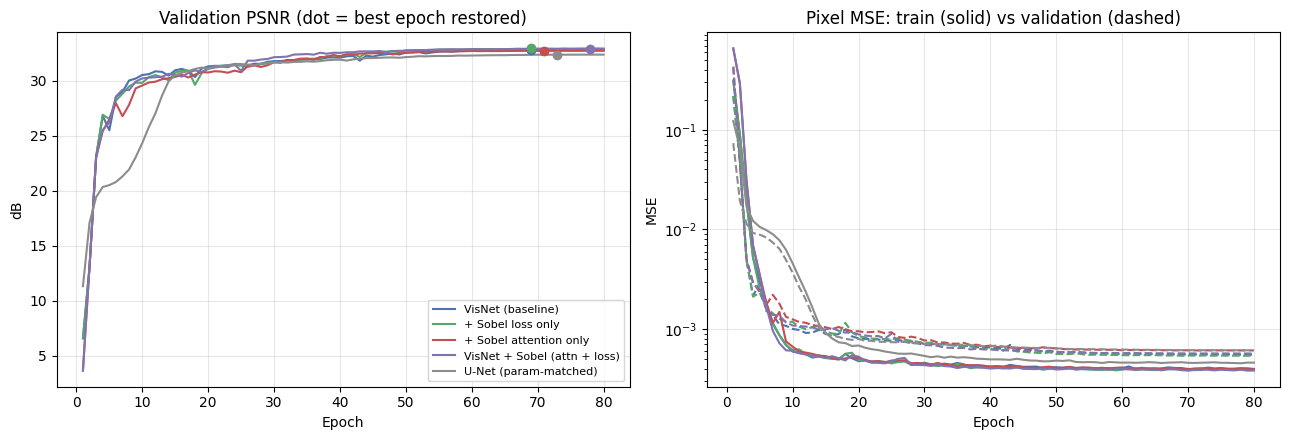

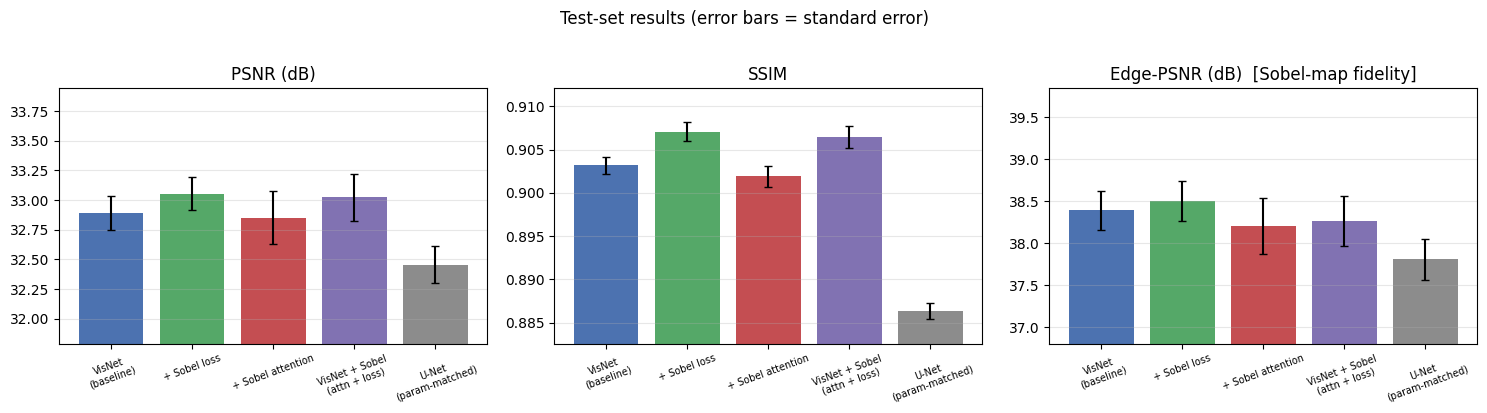

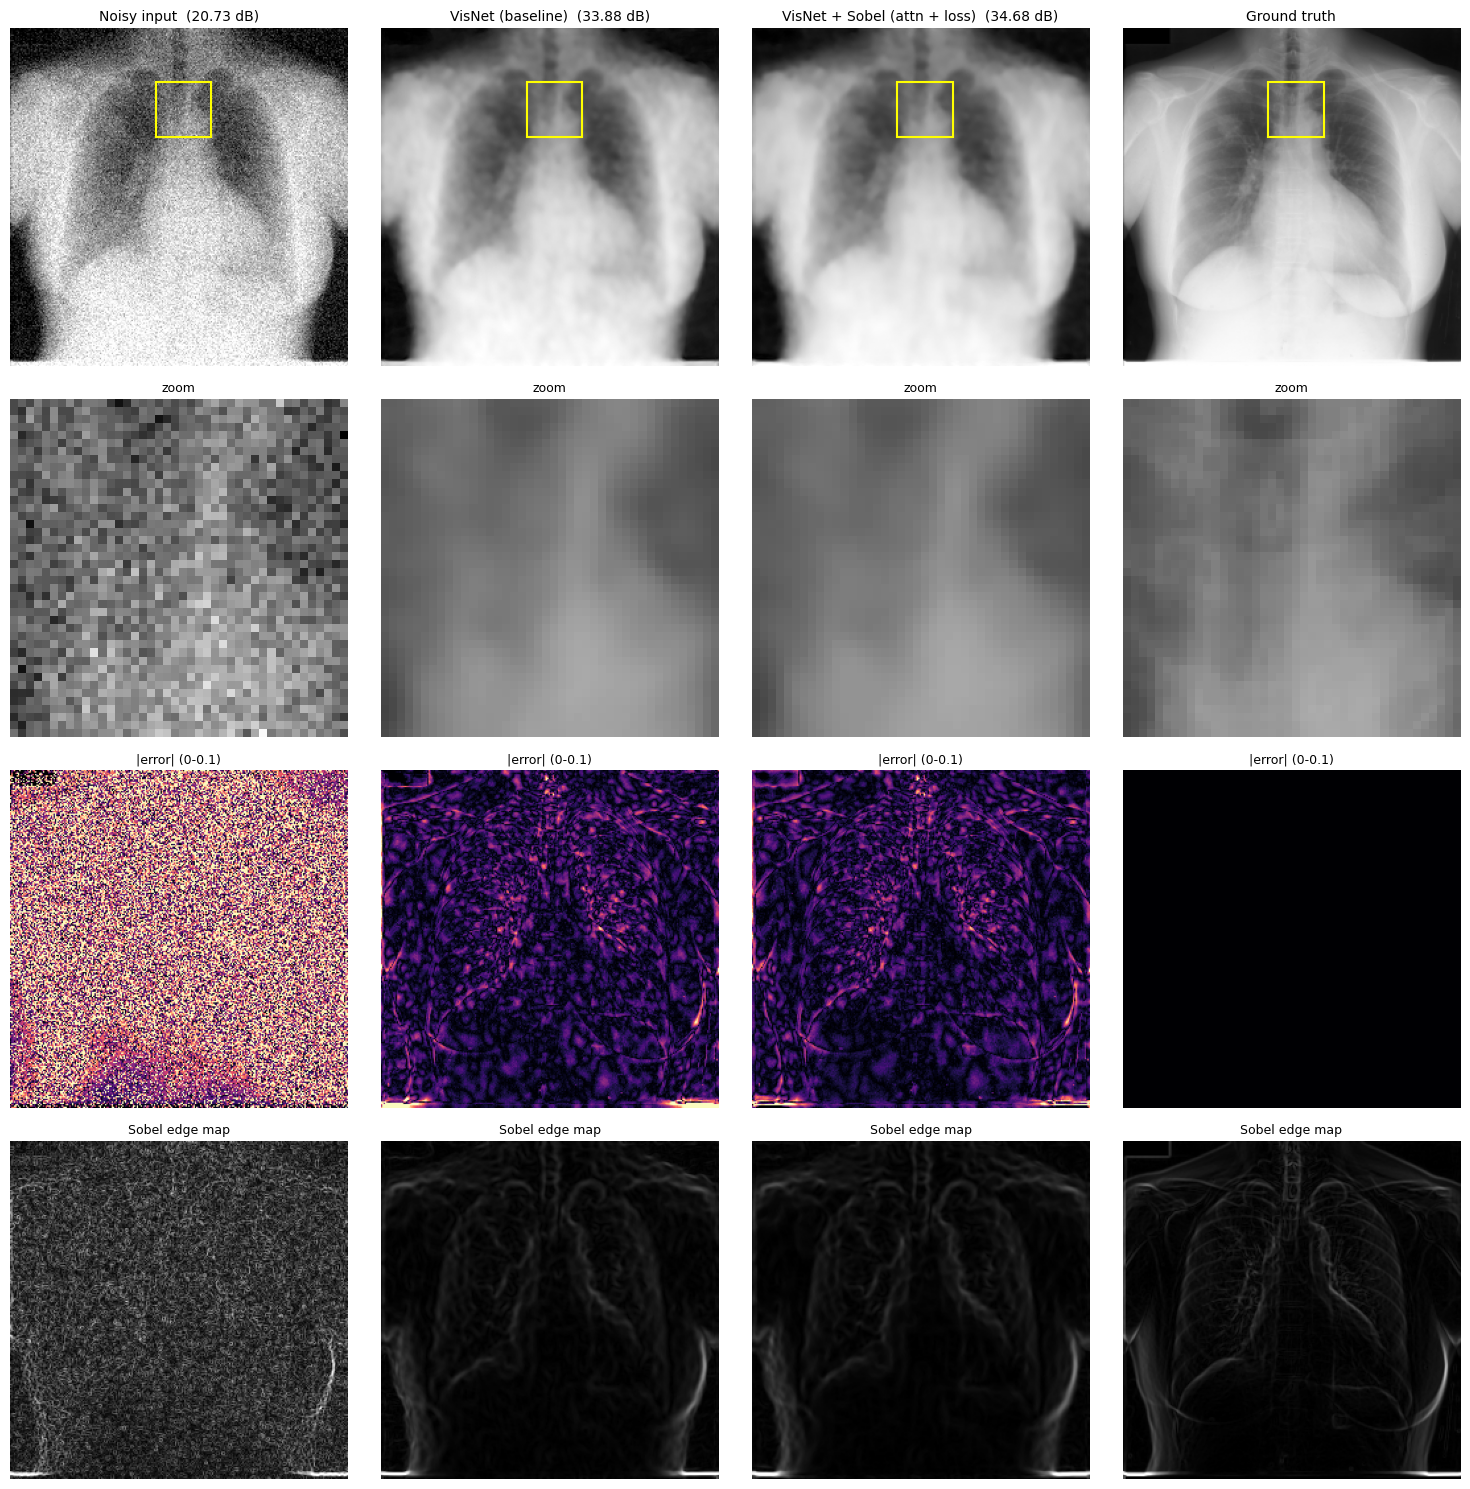

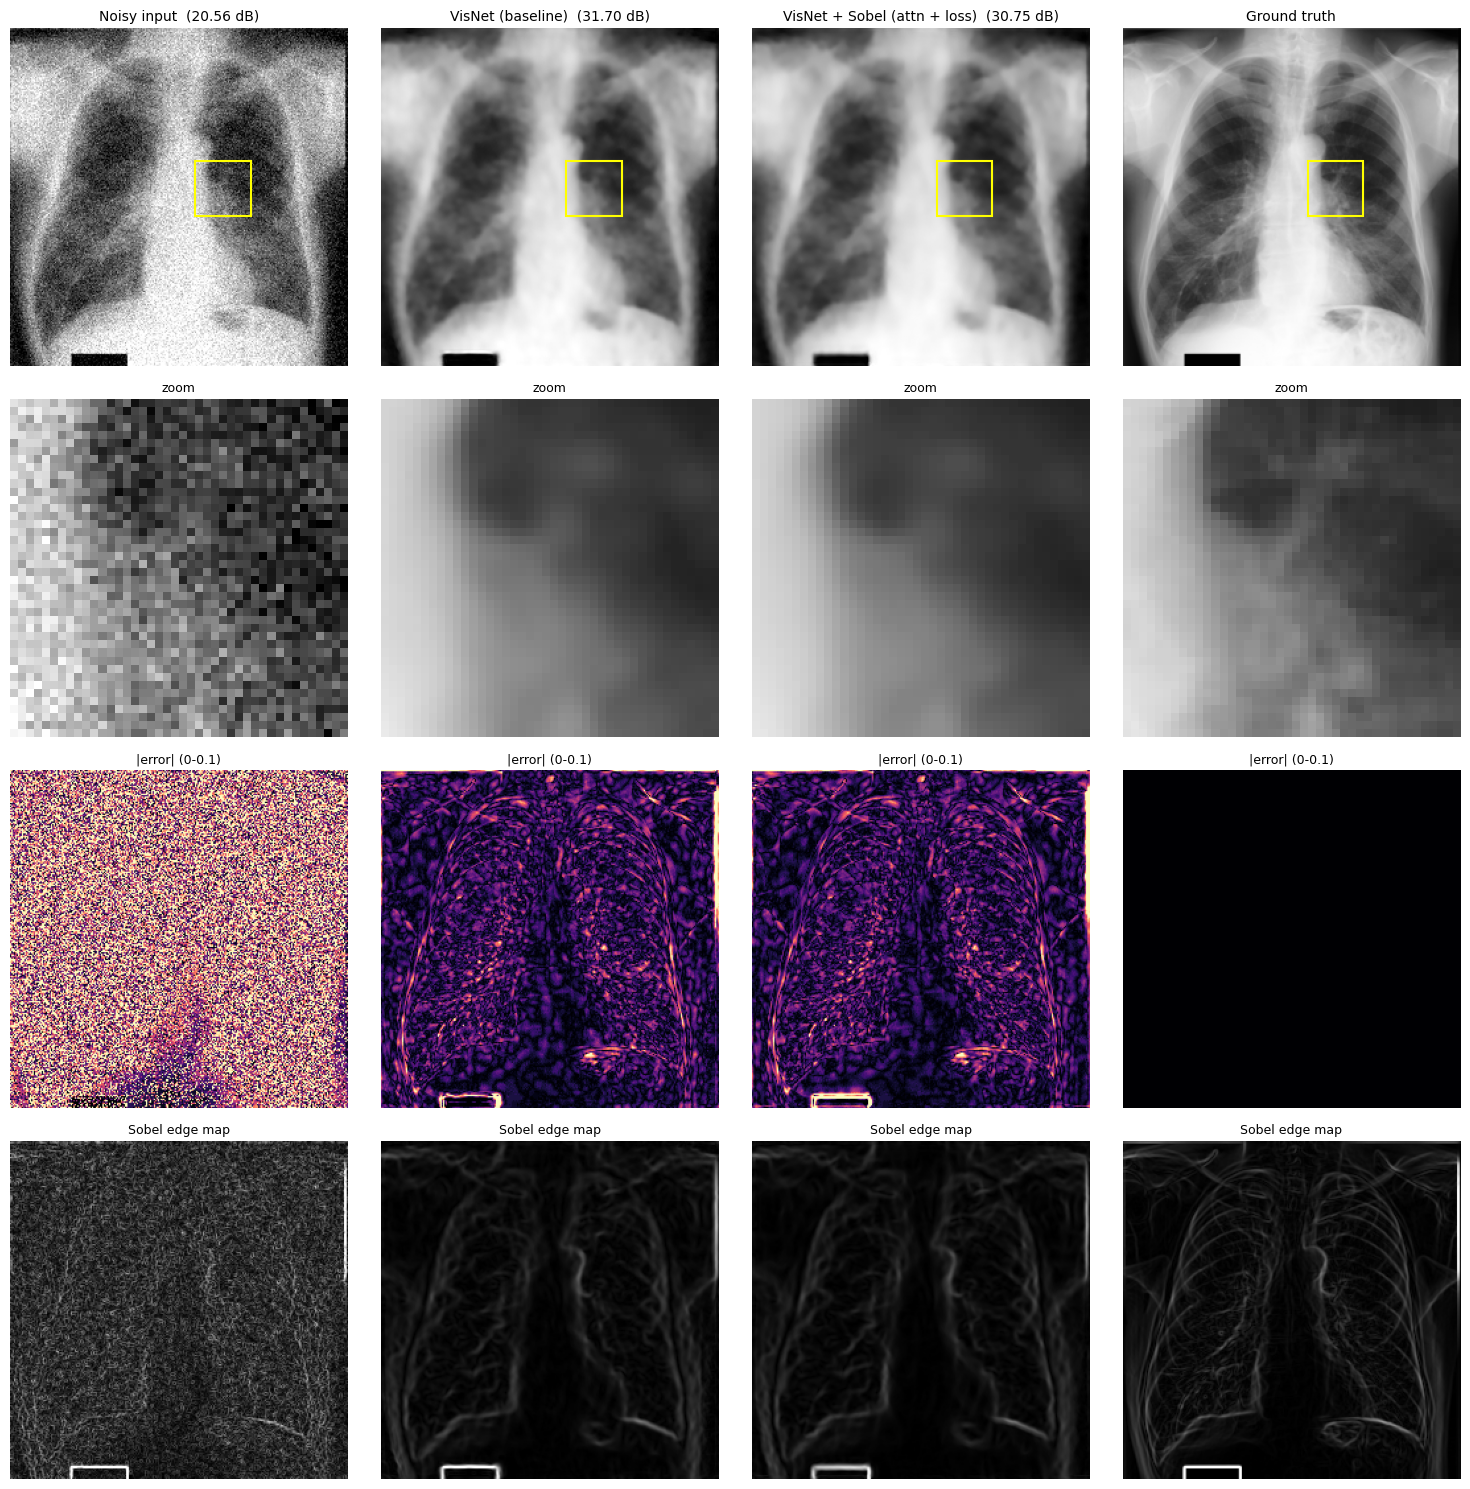

In [11]:
FIG = os.path.join(OUT_DIR, 'figures')
COL = {'VisNet (baseline)': '#4C72B0', '+ Sobel loss only': '#55A868', '+ Sobel attention only': '#C44E52',
       PROPOSED: '#8172B2', 'U-Net (param-matched)': '#8C8C8C'}

# 1) training curves
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for n, r in RESULTS.items():
    h = r['hist']; ax[0].plot(h['epoch'], h['val_psnr'], label=n, color=COL.get(n)); ax[0].scatter(r['best_epoch'], r['best_val_psnr'], color=COL.get(n), zorder=3)
    ax[1].semilogy(h['epoch'], h['train_mse'], color=COL.get(n), label=n + ' (train)'); ax[1].semilogy(h['epoch'], h['val_mse'], '--', color=COL.get(n))
ax[0].set(title='Validation PSNR (dot = best epoch restored)', xlabel='Epoch', ylabel='dB'); ax[0].legend(fontsize=8); ax[0].grid(alpha=.3)
ax[1].set(title='Pixel MSE: train (solid) vs validation (dashed)', xlabel='Epoch', ylabel='MSE'); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.savefig(os.path.join(FIG, 'training_curves.png'), dpi=200); plt.show()

# 2) metric bars
names = [n for n in RESULTS]
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, key, ttl in zip(ax, ['psnr', 'ssim', 'edge_psnr'], ['PSNR (dB)', 'SSIM', 'Edge-PSNR (dB)  [Sobel-map fidelity]']):
    v = [per_img[n][key].mean() for n in names]; e = [per_img[n][key].std() / np.sqrt(len(per_img[n][key])) for n in names]
    a.bar(range(len(names)), v, yerr=e, color=[COL.get(n) for n in names], capsize=3)
    a.set_xticks(range(len(names))); a.set_xticklabels([n.replace(' (', '\n(').replace(' only', '') for n in names], fontsize=7, rotation=20)
    lo = min(v) - 3 * max(e + [1e-3]); a.set_ylim(lo, max(v) + 4 * max(e + [1e-3])); a.set_title(ttl); a.grid(axis='y', alpha=.3)
plt.suptitle('Test-set results (error bars = standard error)', y=1.02); plt.tight_layout(); plt.savefig(os.path.join(FIG, 'metric_bars.png'), dpi=200, bbox_inches='tight'); plt.show()

# 3) qualitative: full image, zoomed ROI on the strongest edges, error map, Sobel map
def roi_box(gt, size):
    e = sobel_mag(gt[None])[0, 0]; H, W = e.shape; m = int(0.18 * H)
    pooled = F.avg_pool2d(e[None, None], size, stride=max(size // 4, 1))[0, 0]
    ph, pw = pooled.shape; st = max(size // 4, 1)
    y0, x0 = max(m // st, 0), max(m // st, 0); y1, x1 = max(ph - m // st, y0 + 1), max(pw - m // st, x0 + 1)
    sub = pooled[y0:y1, x0:x1]; iy, ix = np.unravel_index(sub.argmax().item(), sub.shape)
    return (y0 + iy) * st, (x0 + ix) * st

show = ['Noisy input', 'VisNet (baseline)', PROPOSED, 'Ground truth']
for idx in sorted({0, len(test_u8) // 2}):
    gt = test_clean[idx]; size = max(cfg.img_size // 6, 16); y, x = roi_box(gt, size)
    imgs = {'Noisy input': test_noisy[idx].clamp(0, 1), 'VisNet (baseline)': outputs['VisNet (baseline)'][idx],
            PROPOSED: outputs[PROPOSED][idx], 'Ground truth': gt}
    fig, ax = plt.subplots(4, 4, figsize=(15, 15))
    for j, n in enumerate(show):
        im = imgs[n]; psnr = f"  ({-10*np.log10(((im-gt)**2).mean().item()+1e-12):.2f} dB)" if n != 'Ground truth' else ''
        ax[0, j].imshow(im[0], cmap='gray', vmin=0, vmax=1); ax[0, j].set_title(n + psnr, fontsize=10)
        ax[0, j].add_patch(plt.Rectangle((x, y), size, size, fill=False, ec='yellow', lw=1.5))
        ax[1, j].imshow(im[0, y:y + size, x:x + size], cmap='gray', vmin=0, vmax=1); ax[1, j].set_title('zoom', fontsize=9)
        ax[2, j].imshow((im - gt).abs()[0], cmap='magma', vmin=0, vmax=0.1); ax[2, j].set_title('|error| (0-0.1)', fontsize=9)
        ax[3, j].imshow(sobel_mag(im[None])[0, 0], cmap='gray', vmin=0, vmax=float(sobel_mag(gt[None]).max()) * 0.6); ax[3, j].set_title('Sobel edge map', fontsize=9)
    for a in ax.ravel(): a.axis('off')
    plt.tight_layout(); plt.savefig(os.path.join(FIG, f'qualitative_{idx}.png'), dpi=200); plt.show()

## 11. Summary

In [ ]:
# Summary 
b, p = per_img['VisNet (baseline)'], per_img[PROPOSED]
print("=" * 78)
print(f"TEST SET ({len(test_u8)} held-out images) | noise {cfg.noise_kind} sigma={cfg.sigma*255:.0f}/255 | images {cfg.img_size}x{cfg.img_size}")
print(f"Noisy input        : {per_img['Noisy input']['psnr'].mean():.2f} dB  / SSIM {per_img['Noisy input']['ssim'].mean():.4f}")
print(f"VisNet baseline    : {b['psnr'].mean():.2f} dB  / SSIM {b['ssim'].mean():.4f} / Edge-PSNR {b['edge_psnr'].mean():.2f} dB")
print(f"VisNet + Sobel     : {p['psnr'].mean():.2f} dB  / SSIM {p['ssim'].mean():.4f} / Edge-PSNR {p['edge_psnr'].mean():.2f} dB")
print(f"Improvement        : {p['psnr'].mean()-b['psnr'].mean():+.3f} dB PSNR | {p['ssim'].mean()-b['ssim'].mean():+.4f} SSIM | "
      f"{p['edge_psnr'].mean()-b['edge_psnr'].mean():+.3f} dB Edge-PSNR")
print(f"Params             : {count_params(RESULTS['VisNet (baseline)']['model'])/1e6:.3f} M -> {count_params(RESULTS[PROPOSED]['model'])/1e6:.3f} M")
print("=" * 78)
print("Report the numbers above exactly as they are. If the gain is tiny or negative, say so and use the ablation table to explain it.")
with open(os.path.join(OUT_DIR, 'results.json'), 'w') as f:
    json.dump({'config': asdict(cfg), 'split_sizes': [len(train_u8), len(val_u8), len(test_u8)],
               'training': {k: {kk: vv for kk, vv in v.items() if kk not in ('model', 'hist')} for k, v in RESULTS.items()},
               'test': {k: {m: [float(np.mean(a)), float(np.std(a))] for m, a in v.items()} for k, v in per_img.items()}}, f, indent=1)
print("saved to", OUT_DIR, "->", sorted(os.listdir(OUT_DIR)))

TEST SET (37 held-out images) | noise awgn sigma=25/255 | images 256x256
Noisy input        : 20.65 dB  / SSIM 0.2619
VisNet baseline    : 32.89 dB  / SSIM 0.9032 / Edge-PSNR 38.39 dB
VisNet + Sobel     : 33.02 dB  / SSIM 0.9065 / Edge-PSNR 38.26 dB
Improvement        : +0.132 dB PSNR | +0.0033 SSIM | -0.129 dB Edge-PSNR
Params             : 0.144 M -> 0.145 M
Report the numbers above exactly as they are. If the gain is tiny or negative, say so and use the ablation table to explain it.
saved to /kaggle/working/visnet_out -> ['ckpt_sobel_attention_only.pth', 'ckpt_sobel_loss_only.pth', 'ckpt_u_net_param_matched.pth', 'ckpt_visnet_baseline.pth', 'ckpt_visnet_sobel_attn_loss.pth', 'figures', 'results.json', 'results_table.csv', 'robustness_table.csv']
